# DX799: Week 2: Ridge, Lasso, and Elastic Net Regression

## 1. Goals and methodological choices

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED = 42
DATA_PATH = Path('movies.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('/mnt/data/movies.csv')
raw = pd.read_csv(DATA_PATH)
print('Raw rows and columns:', raw.shape)
print('Columns:', raw.columns.tolist())

Raw rows and columns: (18905, 23)
Columns: ['movie_id', 'title', 'original_title', 'release_date', 'release_year', 'runtime', 'genres', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'original_language', 'production_companies', 'production_countries', 'belongs_to_collection', 'adult', 'imdb_id', 'homepage', 'tagline', 'overview', 'runtime_missing']


## 2. Reproduce Week 1's data preparation

In [2]:
df = raw.drop_duplicates(subset=['movie_id']).copy()
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce')
for col in ['budget', 'revenue', 'runtime']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.loc[
    (df['budget'] > 0) & (df['revenue'] > 0)
    & df['release_year'].between(1980, 2024)
    & df['runtime'].between(40, 240)
    & df['release_date'].notna()
].copy()
df['budget_m'] = df['budget'] / 1_000_000
df['revenue_m'] = df['revenue'] / 1_000_000
df['animation'] = df['genres'].fillna('').str.split('|').apply(lambda x: int('Animation' in x))
df['release_month'] = df['release_date'].dt.month
for genre in ['Action', 'Comedy', 'Drama', 'Horror']:
    df[f'genre_{genre.lower()}'] = df['genres'].fillna('').str.split('|').apply(lambda x: int(genre in x))
for month in range(2, 13):
    df[f'month_{month}'] = (df['release_month'] == month).astype(int)
print(f'Final sample: {len(df):,} movies; animation: {df.animation.sum():,}')
print(df[['budget_m','revenue_m','runtime','release_year']].describe().round(2))

Final sample: 7,079 movies; animation: 376
       budget_m  revenue_m  runtime  release_year
count   7079.00    7079.00  7079.00       7079.00
mean      33.54      90.64   106.89       2004.89
std       43.70     181.95    17.75         11.39
min        0.00       0.00    56.00       1980.00
25%        8.00       5.91    94.00       1997.00
50%       19.00      26.81   104.00       2006.00
75%       40.00      92.85   116.00       2014.00
max      658.80    2923.71   229.00       2024.00


## 3. Feature engineering and train/test split

In [3]:
base = ['budget_m','runtime','release_year','animation',
        'genre_action','genre_comedy','genre_drama','genre_horror'] + [f'month_{i}' for i in range(2, 13)]
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED)
train, test = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
budget_train_mean = train['budget_m'].mean()
for frame in (train, test):
    frame['budget_centered_sq'] = (frame['budget_m'] - budget_train_mean)**2
    frame['budget_animation'] = (frame['budget_m'] - budget_train_mean) * frame['animation']
expanded = base + ['budget_centered_sq', 'budget_animation']
X_train, X_test = train[expanded], test[expanded]
y_train, y_test = train['revenue_m'], test['revenue_m']
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print('Training rows:', len(train), 'Test rows:', len(test), 'Expanded predictors:', len(expanded))

Training rows: 5663 Test rows: 1416 Expanded predictors: 21


## 4. Tune regularization using training-only cross-validation

In [4]:
candidates = {
    'Ridge': (Ridge(), {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Lasso': (Lasso(max_iter=30000, random_state=SEED), {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}),
    'Elastic Net': (ElasticNet(max_iter=30000, random_state=SEED),
                    {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100],
                     'model__l1_ratio': [0.2, 0.5, 0.8]})
}
searches = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for name, (regressor, param_grid) in candidates.items():
        pipe = Pipeline([('scale', StandardScaler()), ('model', regressor)])
        search = GridSearchCV(pipe, param_grid, scoring='neg_root_mean_squared_error',
                              cv=cv, n_jobs=-1, refit=True)
        search.fit(X_train, y_train)
        searches[name] = search
        print(f'{name}: CV RMSE ${-search.best_score_:,.2f}M; best parameters: {search.best_params_}')

Ridge: CV RMSE $125.90M; best parameters: {'model__alpha': 100}
Lasso: CV RMSE $125.93M; best parameters: {'model__alpha': 1}


Elastic Net: CV RMSE $125.90M; best parameters: {'model__alpha': 0.1, 'model__l1_ratio': 0.5}


## 5. Compare test performance and overfitting

In [5]:
models = {
    'Week 1 linear controls': LinearRegression().fit(train[base], y_train),
    'Week 1 expanded OLS': LinearRegression().fit(X_train, y_train),
    **{name: search.best_estimator_ for name, search in searches.items()}
}
rows = []
for name, model in models.items():
    cols = base if name == 'Week 1 linear controls' else expanded
    pred_train, pred_test = model.predict(train[cols]), model.predict(test[cols])
    rows.append({'Model': name,
                 'Train R2': r2_score(y_train, pred_train),
                 'Test R2': r2_score(y_test, pred_test),
                 'Train RMSE ($M)': np.sqrt(mean_squared_error(y_train, pred_train)),
                 'Test RMSE ($M)': np.sqrt(mean_squared_error(y_test, pred_test)),
                 'Test MAE ($M)': mean_absolute_error(y_test, pred_test)})
results = pd.DataFrame(rows).set_index('Model')
print(results.round(3).to_string())
print('Lowest training-selected CV RMSE:', min(searches, key=lambda m: -searches[m].best_score_))

                        Train R2  Test R2  Train RMSE ($M)  Test RMSE ($M)  Test MAE ($M)
Model                                                                                    
Week 1 linear controls     0.545    0.514          125.937         112.443         63.953
Week 1 expanded OLS        0.558    0.389          124.146         126.028         62.976
Ridge                      0.558    0.383          124.166         126.613         62.976
Lasso                      0.558    0.397          124.222         125.218         62.225
Elastic Net                0.557    0.378          124.274         127.214         63.015
Lowest training-selected CV RMSE: Elastic Net


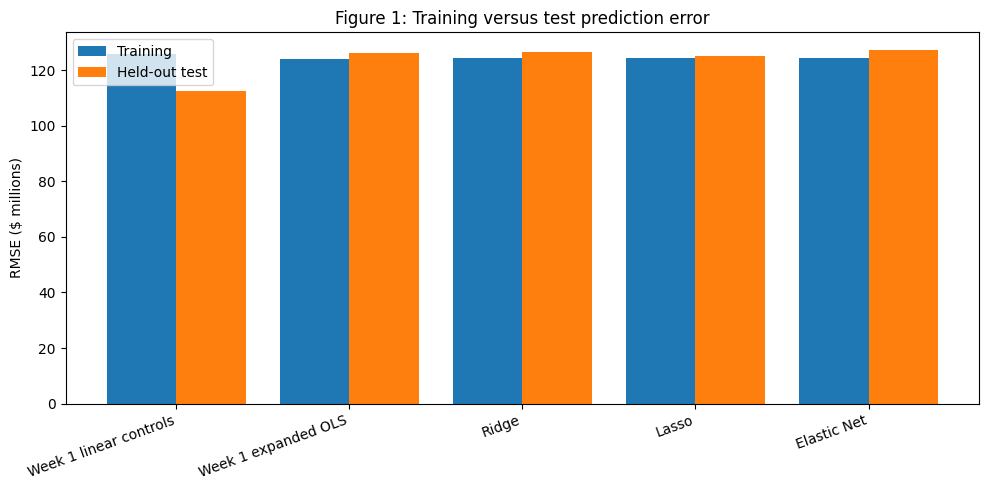

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
order = results.index.tolist()
x = np.arange(len(order))
ax.bar(x-0.2, results['Train RMSE ($M)'], width=0.4, label='Training')
ax.bar(x+0.2, results['Test RMSE ($M)'], width=0.4, label='Held-out test')
ax.set_xticks(x, order, rotation=20, ha='right')
ax.set_ylabel('RMSE ($ millions)')
ax.set_title('Figure 1: Training versus test prediction error')
ax.legend(); plt.tight_layout(); plt.show()

## 6. Understanding shrinkage and feature selection

Numbers of coefficients effectively zero (absolute value under 1e-6):
Expanded OLS: 0 of 21
Ridge: 0 of 21
Lasso: 3 of 21
Elastic Net: 0 of 21
Largest coefficients in Lasso (revenue $M per 1 SD of predictor):
budget_m              94.749
budget_centered_sq    31.729
runtime               19.364
genre_drama          -11.402
budget_animation       9.504
animation              9.430
month_6                7.776
month_5                4.521
month_7                3.054
month_12               2.548
month_8               -2.108
genre_comedy           2.035
Name: Lasso, dtype: float64


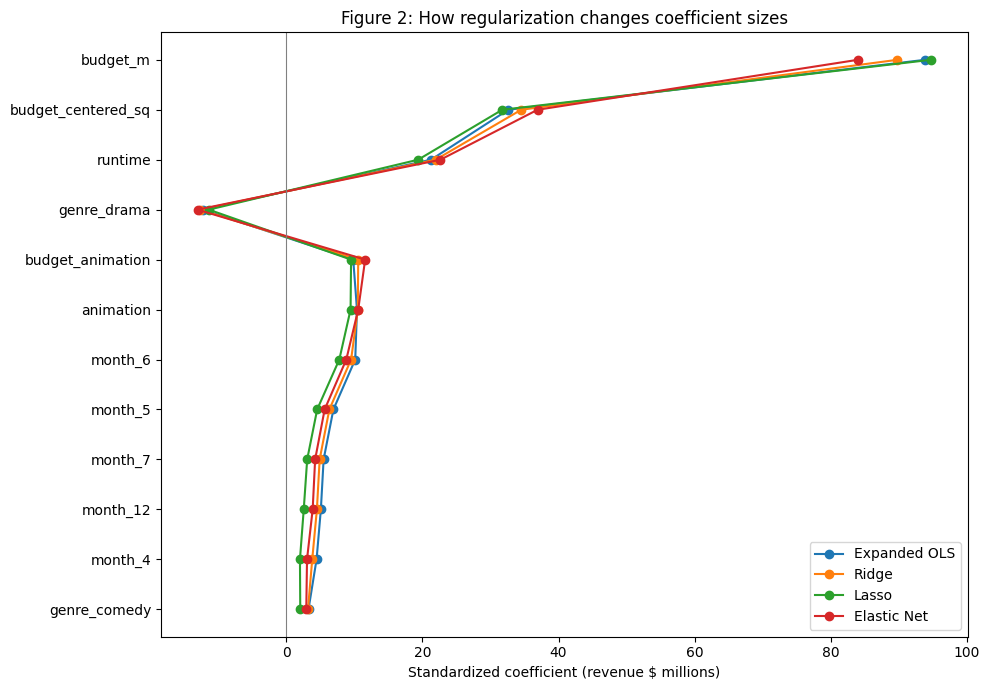

In [7]:
scaled_ols = Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]).fit(X_train, y_train)
coef = {'Expanded OLS': scaled_ols.named_steps['model'].coef_}
for name in ['Ridge','Lasso','Elastic Net']:
    coef[name] = models[name].named_steps['model'].coef_
coefs = pd.DataFrame(coef, index=expanded)
print('Numbers of coefficients effectively zero (absolute value under 1e-6):')
for name in coefs.columns:
    print(f'{name}: {np.sum(np.abs(coefs[name].values) < 1e-6)} of {len(expanded)}')
print('Largest coefficients in Lasso (revenue $M per 1 SD of predictor):')
print(coefs['Lasso'].reindex(coefs['Lasso'].abs().sort_values(ascending=False).index).head(12).round(3))
fig, ax = plt.subplots(figsize=(10, 7))
show = coefs.abs().max(axis=1).nlargest(12).index[::-1]
for name in coefs.columns:
    ax.plot(coefs.loc[show, name], range(len(show)), marker='o', label=name)
ax.set_yticks(range(len(show)), show)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set(xlabel='Standardized coefficient (revenue $ millions)', title='Figure 2: How regularization changes coefficient sizes')
ax.legend(); plt.tight_layout(); plt.show()

## 7. Validation profiles and parameter interpretation

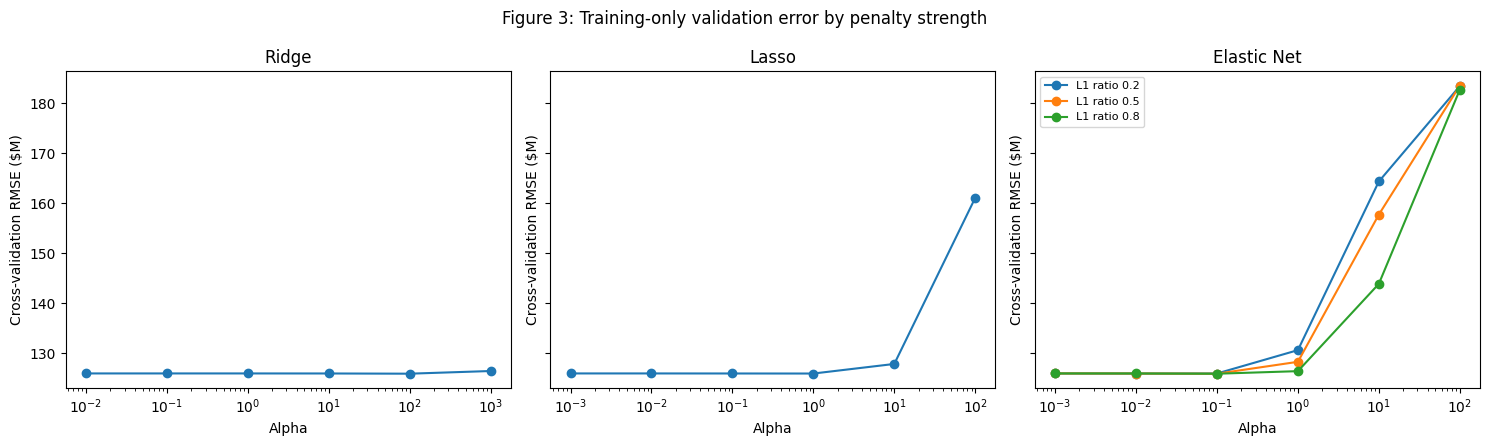

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, ['Ridge','Lasso','Elastic Net']):
    r = pd.DataFrame(searches[name].cv_results_)
    if name != 'Elastic Net':
        ax.plot(r['param_model__alpha'].astype(float), -r['mean_test_score'], marker='o')
    else:
        for ratio, subset in r.groupby('param_model__l1_ratio'):
            sub = subset.sort_values('param_model__alpha')
            ax.plot(sub['param_model__alpha'].astype(float), -sub['mean_test_score'], marker='o', label=f'L1 ratio {ratio}')
        ax.legend(fontsize=8)
    ax.set_xscale('log'); ax.set_title(name)
    ax.set(xlabel='Alpha', ylabel='Cross-validation RMSE ($M)')
fig.suptitle('Figure 3: Training-only validation error by penalty strength')
plt.tight_layout(); plt.show()

## 8. Held-out prediction accuracy and residual patterns

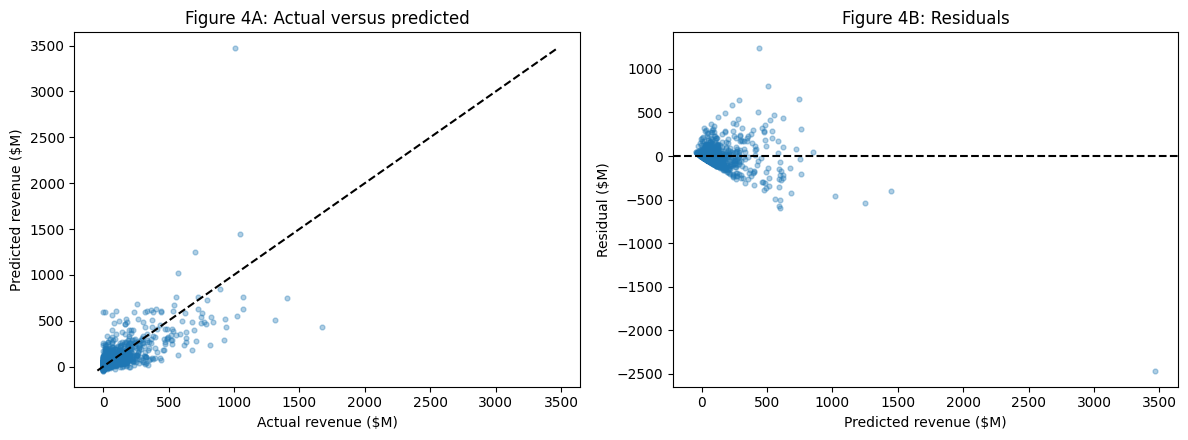

CV-selected regularized model: Elastic Net
Held-out performance: {'Train R2': 0.557, 'Test R2': 0.378, 'Train RMSE ($M)': 124.274, 'Test RMSE ($M)': 127.214, 'Test MAE ($M)': 63.015}


In [9]:
chosen = min(searches, key=lambda m: -searches[m].best_score_)
final_model = models[chosen]
y_pred = final_model.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, y_pred, s=12, alpha=0.35)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
ax[0].plot([lo, hi],[lo, hi], linestyle='--', color='black')
ax[0].set(xlabel='Actual revenue ($M)', ylabel='Predicted revenue ($M)', title='Figure 4A: Actual versus predicted')
ax[1].scatter(y_pred, y_test-y_pred, s=12, alpha=0.35)
ax[1].axhline(0, linestyle='--', color='black')
ax[1].set(xlabel='Predicted revenue ($M)', ylabel='Residual ($M)', title='Figure 4B: Residuals')
plt.tight_layout(); plt.show()
print('CV-selected regularized model:', chosen)
print('Held-out performance:', results.loc[chosen].round(3).to_dict())

## 9. Results and implications for the Capstone

In [10]:
ols = results.loc['Week 1 expanded OLS']
baseline = results.loc['Week 1 linear controls']
cv_choice = chosen
picked = results.loc[cv_choice]
print(f'Analyzed {len(df):,} movies, with {len(train):,} training and {len(test):,} test cases.')
print(f'Week 1 linear-controls holdout R²: {baseline["Test R2"]:.3f}, RMSE: ${baseline["Test RMSE ($M)"]:.2f}M.')
print(f'Expanded OLS holdout R²: {ols["Test R2"]:.3f}, RMSE: ${ols["Test RMSE ($M)"]:.2f}M.')
print(f'Best tuned regularized model by training CV: {cv_choice}, with mean CV RMSE ${-searches[cv_choice].best_score_:.2f}M.')
print(f'{cv_choice} holdout R²: {picked["Test R2"]:.3f}; RMSE: ${picked["Test RMSE ($M)"]:.2f}M; MAE: ${picked["Test MAE ($M)"]:.2f}M.')
print(f'Change in held-out RMSE versus expanded OLS: ${picked["Test RMSE ($M)"]-ols["Test RMSE ($M)"]:+.2f}M (negative means improvement).')
print(f'Lasso zero coefficients: {(np.abs(coefs["Lasso"].values)<1e-6).sum()} of {len(expanded)}.')
print('Interpretation: Penalization can reduce coefficient instability, but improved test performance must be demonstrated, not assumed.')

Analyzed 7,079 movies, with 5,663 training and 1,416 test cases.
Week 1 linear-controls holdout R²: 0.514, RMSE: $112.44M.
Expanded OLS holdout R²: 0.389, RMSE: $126.03M.
Best tuned regularized model by training CV: Elastic Net, with mean CV RMSE $125.90M.
Elastic Net holdout R²: 0.378; RMSE: $127.21M; MAE: $63.01M.
Change in held-out RMSE versus expanded OLS: $+1.19M (negative means improvement).
Lasso zero coefficients: 3 of 21.
Interpretation: Penalization can reduce coefficient instability, but improved test performance must be demonstrated, not assumed.
